# Model Design and training

1 - Before architecture considerations

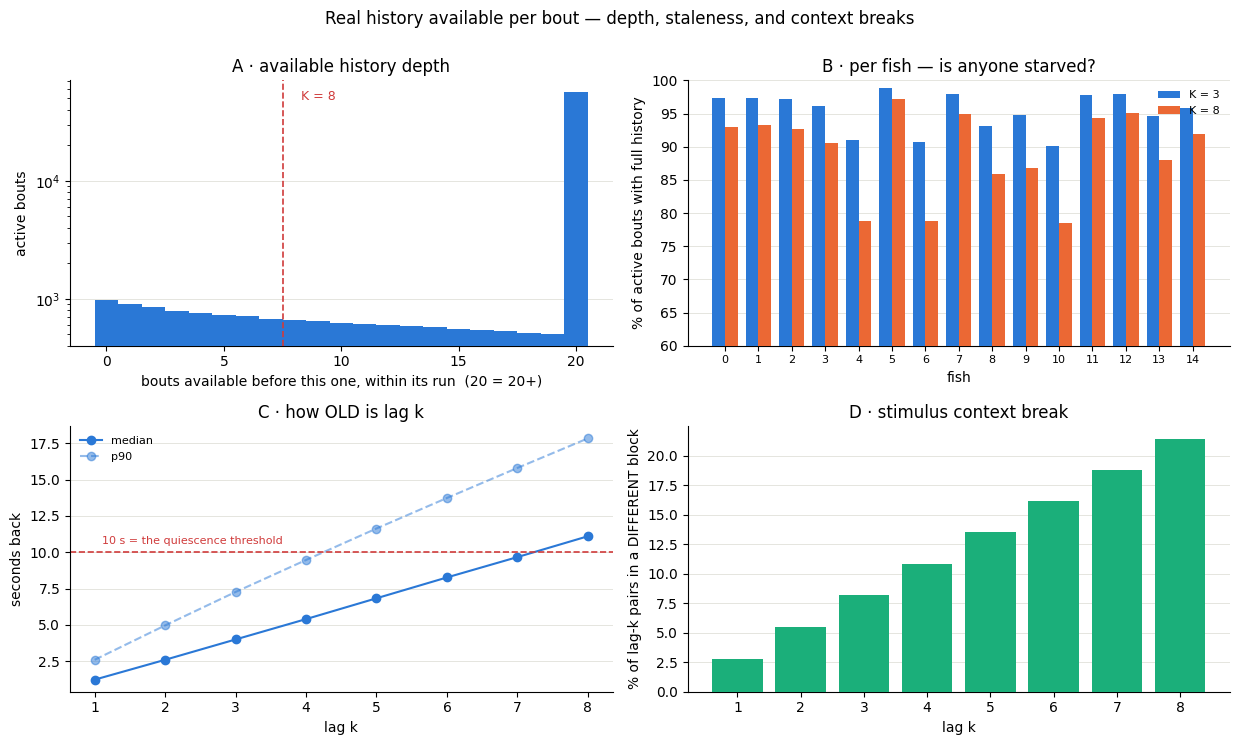

     depth_ok  med_s  p90_s  over10  cross
lag                                       
1        98.6    1.2    2.6     0.0    2.7
2        97.3    2.6    5.0     0.9    5.4
3        96.1    4.0    7.3     3.4    8.2
4        94.9    5.4    9.5     8.3   10.9
5        93.8    6.8   11.6    16.7   13.5
6        92.8    8.3   13.7    29.8   16.1
7        91.8    9.7   15.8    45.9   18.8
8        90.8   11.1   17.8    62.3   21.4

fish with the least history:
 fish  K3_%  K8_%  median_run
   10  90.1  78.5           9
    6  90.8  78.7          17
    4  90.9  78.8          19
    8  93.1  85.8           7
    9  94.7  86.7          25

Note median_run is misleading: fish 14 has a median run of 4 bouts but 92 % of its
bouts still have K=8 history, because the mass sits in a few long runs.

If sequences were cut at BLOCK boundaries too (2,855 segments, median 25 bouts):
   K=1:  95.9 % keep full history   (run-only:  98.6 %)
   K=3:  88.2 % keep full history   (run-only:  96.1 %)
   K=5:  8

In [1]:
# How much history does a bout ACTUALLY have?
#
# Cutting sequences at quiescence gaps means the first K bouts of every run have no full
# lag window. Two separate questions follow, and they have different answers:
#   (a) DEPTH  -- how many previous bouts exist inside the same run
#   (b) STALENESS -- how far BACK IN TIME lag k reaches, and whether the stimulus changed
# (b) is the one that bites: within a run, dt is unbounded below 10 s, so lag 8 can sit
# 11 s and a block boundary away -- a different stimulus context presented as continuous.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "clean_data").exists() and (ROOT.parent / "clean_data").exists():
    ROOT = ROOT.parent

d = pd.read_csv(ROOT / "clean_data" / "bouts_clean.csv")
a = d[d.active].copy()
a["pos"] = a.groupby("run_id").cumcount()          # available depth: 0 = first of its run
g = a.groupby("run_id")
FISH = sorted(a.fish_id.unique())
KMAX = 8
INK, BLUE, ORANGE, AQUA, GRID = "#0b0b0b", "#2a78d6", "#eb6834", "#1baf7a", "#e1e0d9"

# --- staleness table -----------------------------------------------------------
rows = []
for k in range(1, KMAX + 1):
    back = a.t_onset_s - g["t_onset_s"].shift(k)
    xblk = g["blk"].shift(k) != a.blk
    m = back.notna()
    rows.append(dict(lag=k, depth_ok=100 * (a["pos"] >= k).mean(),
                     med_s=back[m].median(), p90_s=back[m].quantile(.9),
                     over10=100 * (back[m] > 10).mean(),
                     cross=100 * xblk[m].mean()))
S = pd.DataFrame(rows).set_index("lag")

fig, ax = plt.subplots(2, 2, figsize=(12.5, 7.4))

# A. available depth, pooled
h = np.clip(a["pos"], 0, 20)
ax[0, 0].hist(h, bins=np.arange(-.5, 21.5), color=BLUE, zorder=3)
ax[0, 0].axvline(KMAX - .5, color="#d03b3b", ls="--", lw=1.2, zorder=4)
ax[0, 0].text(KMAX + .3, ax[0, 0].get_ylim()[1] * .82, f"K = {KMAX}", color="#d03b3b", fontsize=9)
ax[0, 0].set_yscale("log")
ax[0, 0].set_xlabel("bouts available before this one, within its run  (20 = 20+)")
ax[0, 0].set_ylabel("active bouts")
ax[0, 0].set_title("A · available history depth")

# B. one bar per fish -- the scalar that matters
w = .38
pk3 = [100 * (a.loc[a.fish_id == f, "pos"] >= 3).mean() for f in FISH]
pk8 = [100 * (a.loc[a.fish_id == f, "pos"] >= 8).mean() for f in FISH]
x = np.arange(len(FISH))
ax[0, 1].bar(x - w / 2, pk3, w, color=BLUE, label="K = 3", zorder=3)
ax[0, 1].bar(x + w / 2, pk8, w, color=ORANGE, label="K = 8", zorder=3)
ax[0, 1].set_xticks(x); ax[0, 1].set_xticklabels(FISH, fontsize=8)
ax[0, 1].set_ylim(60, 100)
ax[0, 1].set_xlabel("fish"); ax[0, 1].set_ylabel("% of active bouts with full history")
ax[0, 1].set_title("B · per fish — is anyone starved?")
ax[0, 1].legend(fontsize=8, frameon=False)

# C. staleness: how far back lag k reaches
ax[1, 0].plot(S.index, S.med_s, "o-", color=BLUE, label="median")
ax[1, 0].plot(S.index, S.p90_s, "o--", color=BLUE, alpha=.5, label="p90")
ax[1, 0].axhline(10, color="#d03b3b", ls="--", lw=1.2)
ax[1, 0].text(1.1, 10.6, "10 s = the quiescence threshold", color="#d03b3b", fontsize=8)
ax[1, 0].set_xlabel("lag k"); ax[1, 0].set_ylabel("seconds back")
ax[1, 0].set_title("C · how OLD is lag k")
ax[1, 0].legend(fontsize=8, frameon=False)

# D. does the stimulus context change across the lag?
ax[1, 1].bar(S.index, S.cross, color=AQUA, zorder=3)
ax[1, 1].set_xlabel("lag k")
ax[1, 1].set_ylabel("% of lag-k pairs in a DIFFERENT block")
ax[1, 1].set_title("D · stimulus context break")
for axx in ax.ravel():
    axx.grid(axis="y", color=GRID, lw=.6, zorder=0)
    axx.set_axisbelow(True)
    axx.spines[["top", "right"]].set_visible(False)
fig.suptitle("Real history available per bout — depth, staleness, and context breaks", y=1.0)
fig.tight_layout()
plt.show()

print(S.round(1).to_string())
print()
worst = pd.DataFrame({"fish": FISH, "K3_%": np.round(pk3, 1), "K8_%": np.round(pk8, 1),
                      "median_run": [int(a[a.fish_id == f].groupby("run_id").size().median())
                                     for f in FISH]}).sort_values("K8_%").head(5)
print("fish with the least history:")
print(worst.to_string(index=False))
print("\nNote median_run is misleading: fish 14 has a median run of 4 bouts but 92 % of its")
print("bouts still have K=8 history, because the mass sits in a few long runs.")

# --- what cutting at block boundaries as well would cost -----------------------
a["seg"] = a.run_id.astype(str) + "_" + a.blk.astype(str)
a["bpos"] = a.groupby("seg").cumcount()
print(f"\nIf sequences were cut at BLOCK boundaries too "
      f"({a.seg.nunique():,} segments, median "
      f"{int(a.groupby('seg').size().median())} bouts):")
for K in (1, 3, 5, 8):
    print(f"   K={K}: {100*(a['bpos'] >= K).mean():5.1f} % keep full history"
          f"   (run-only: {100*(a['pos'] >= K).mean():5.1f} %)")

To work around this issue we use padding, at the cost of having some bouts conditioned on less information than others, but using all the information available. 

In [2]:
# Build the lag block ON the dataframe: zero-padded at run starts, plus the validity
# flags that make padding distinguishable from a real value.
#
# WHY the flags are needed: the turn lags are raw degrees, so a padded slot is exactly 0 --
# which is also what a perfectly straight bout gives. Without a validity column the net
# cannot tell "no previous bout" from "the previous bout went straight", and straight-ish
# is the modal behaviour, so every run start would inject a plausible fake observation.
K_TURN, K_KIN = 8, 3

a = d[d.active].copy().sort_values(["fish_id", "bout_index"]).reset_index(drop=True)
a["run_pos"] = a.groupby("run_id").cumcount()          # 0 = first bout of its run
g = a.groupby("run_id")

for k in range(1, K_TURN + 1):
    a[f"dtheta_lag{k}"] = g["dtheta_deg"].shift(k).fillna(0.0)   # pad = 0, as _history_block
    a[f"lag{k}_valid"] = (a["run_pos"] >= k).astype("int8")
for k in range(1, K_KIN + 1):
    a[f"dist_lag{k}"] = g["distance_px"].shift(k).fillna(0.0)
    a[f"dt_lag{k}"] = g["dt_s"].shift(k).fillna(0.0)
a["n_valid_lags"] = np.minimum(a["run_pos"], K_TURN).astype("int16")

new = [c for c in a.columns if "lag" in c or c in ("run_pos", "n_valid_lags")]
print(f"{len(a):,} active bouts   {len(new)} new columns "
      f"({K_TURN} turn lags + {K_TURN} validity flags + {K_KIN} dist + {K_KIN} dt + 2)")

# --- show it working ACROSS a run boundary, where padding is visible ------------
starts = a.index[(a.run_pos == 0) & (a.index > 6)]
b = int(starts[3])
cols = (["fish_id", "run_id", "run_pos", "dtheta_deg"]
        + [f"dtheta_lag{k}" for k in (1, 2, 3)]
        + [f"lag{k}_valid" for k in (1, 2, 3)] + ["n_valid_lags"])
print(f"\nrows {b-3}..{b+4} — a run boundary at index {b} "
      f"(run {a.run_id[b-1]} -> {a.run_id[b]}):")
print(a.loc[b - 3:b + 4, cols].to_string(index=False))

print("\nThe first row of the new run has every lag padded to 0.0 and every validity flag 0;")
print("by run_pos = 3 the first three lags are real again and n_valid_lags has caught up.")

pad = 100 * (1 - a[[f"lag{k}_valid" for k in range(1, K_TURN + 1)]].to_numpy().mean())
near0 = 100 * (a.dtheta_deg.abs() < 1).mean()
print(f"\npadded slots: {pad:.1f} % of all {K_TURN} x {len(a):,} turn-lag entries")
print(f"real |dtheta| < 1 deg: {near0:.1f} % of bouts -- these are the values a padded 0 is")
print("indistinguishable from, which is exactly what the validity flags separate.")

a.head()

69,572 active bouts   24 new columns (8 turn lags + 8 validity flags + 3 dist + 3 dt + 2)

rows 767..774 — a run boundary at index 770 (run 5 -> 7):
 fish_id  run_id  run_pos  dtheta_deg  dtheta_lag1  dtheta_lag2  dtheta_lag3  lag1_valid  lag2_valid  lag3_valid  n_valid_lags
       0       5      429  -67.166346   -50.710593    -4.780884   -34.508523           1           1           1             8
       0       5      430  -67.833654   -67.166346   -50.710593    -4.780884           1           1           1             8
       0       5      431  -40.236358   -67.833654   -67.166346   -50.710593           1           1           1             8
       0       7        0   -3.814075     0.000000     0.000000     0.000000           0           0           0             0
       0       7        1  -56.117342    -3.814075     0.000000     0.000000           1           0           0             1
       0       7        2   59.931417   -56.117342    -3.814075     0.000000           1 

,fish_id,segment_id,bout_index,frame_onset,t_onset_s,dtheta_rad,dtheta_deg,dtheta_ori_deg,dt_s,distance_px,...,lag7_valid,dtheta_lag8,lag8_valid,dist_lag1,dt_lag1,dist_lag2,dt_lag2,dist_lag3,dt_lag3,n_valid_lags
0,0,0,1,218,7.266667,-0.965252,-55.304846,-73.224006,2.900000,26.870058,...,0,0.0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
1,0,0,2,305,10.166667,0.680521,38.990994,31.913749,2.766667,19.104973,...,0,0.0,0,26.870058,2.900000,0.000000,0.000000,0.000000,0.0,1
2,0,0,3,388,12.933333,-0.402222,-23.045598,-14.553128,0.933333,10.295630,...,0,0.0,0,19.104973,2.766667,26.870058,2.900000,0.000000,0.0,2
3,0,0,4,416,13.866667,-0.033321,-1.909152,-2.750197,1.566667,11.661904,...,0,0.0,0,10.295630,0.933333,19.104973,2.766667,26.870058,2.9,3
4,0,0,7,855,28.500000,-0.058756,-3.366461,-9.568395,1.100000,9.899495,...,0,0.0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0


In [3]:
a[a.fish_id == 0].head(15)

,fish_id,segment_id,bout_index,frame_onset,t_onset_s,dtheta_rad,dtheta_deg,dtheta_ori_deg,dt_s,distance_px,...,lag7_valid,dtheta_lag8,lag8_valid,dist_lag1,dt_lag1,dist_lag2,dt_lag2,dist_lag3,dt_lag3,n_valid_lags
0,0,0,1,218,7.266667,-0.965252,-55.304846,-73.224006,2.900000,26.870058,...,0,0.000000,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0
1,0,0,2,305,10.166667,0.680521,38.990994,31.913749,2.766667,19.104973,...,0,0.000000,0,26.870058,2.900000,0.000000,0.000000,0.000000,0.000000,1
2,0,0,3,388,12.933333,-0.402222,-23.045598,-14.553128,0.933333,10.295630,...,0,0.000000,0,19.104973,2.766667,26.870058,2.900000,0.000000,0.000000,2
3,0,0,4,416,13.866667,-0.033321,-1.909152,-2.750197,1.566667,11.661904,...,0,0.000000,0,10.295630,0.933333,19.104973,2.766667,26.870058,2.900000,3
4,0,0,7,855,28.500000,-0.058756,-3.366461,-9.568395,1.100000,9.899495,...,0,0.000000,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0
5,0,0,8,888,29.600000,-0.661043,-37.874984,-27.387383,3.733333,16.124515,...,0,0.000000,0,9.899495,1.100000,0.000000,0.000000,0.000000,0.000000,1
6,0,0,9,1000,33.333333,0.000000,0.000000,-6.589015,2.100000,8.062258,...,0,0.000000,0,16.124515,3.733333,9.899495,1.100000,0.000000,0.000000,2
7,0,0,10,1063,35.433333,-0.881190,-50.488439,-57.100553,2.366667,24.758837,...,0,0.000000,0,8.062258,2.100000,16.124515,3.733333,9.899495,1.100000,3
8,0,0,11,1134,37.800000,-0.628614,-36.016922,-36.474072,1.700000,16.278821,...,0,0.000000,0,24.758837,2.366667,8.062258,2.100000,16.124515,3.733333,4
9,0,0,12,1185,39.500000,-0.114040,-6.534038,-14.782311,1.700000,14.035669,...,0,0.000000,0,16.278821,1.700000,24.758837,2.366667,8.062258,2.100000,5


### Recap - Input features

##### These are columns, not input dimensions

The lag columns above are the **lag-1 seed** of a history block the feature builder expands.
`fit_MLP_border.build_feature_matrix` concatenates the blocks below **in this order**, which is
the actual layout of `x`.

| # | block | built from | dims | config key |
|---|---|---|---|---|
| 1 | turn history | `dtheta_deg`, K lags | K (8 typical) | `K` |
| 2 | symbols | one-hot of the previous K symbols | 3K | `include_symbols` (off) |
| 3 | stimulus | `stim_mode` | 6 S1 · 7 S2 · 13 S3 `shoalr` · **18 S4 `shoal`** · 21 `shoalf` | `stim_mode` |
| 4 | stimulus memory | previous stimulus onsets | 1 + 4·(K_stim − 1) | `K_stim > 1` |
| 5 | wall | `dist_to_border_norm`, sin ψ, cos ψ | **3** raw · **9** basis | `use_border` |
| 6 | adaptation | `dot_prox` − its leaky integral | 2 | `use_adapt` |
| 7 | kinematic history | `distance_px`, `dt_s`, K_kin lags | 2 × K_kin (6 at K_kin = 3) | `use_kin` |
| 8 | **lag validity** | `_history_block`'s padding pattern | **K** mask · **1** scalar | `lag_valid='mask'\|'scalar'` |
| 9 | **block clock** | time into the current stimulus block | **1** | `clock_mode='linear'\|'exp'` |


**Not a column of `x`: the per-fish latent `z`.** `fish_id` indexes it during fitting; at
generation it is drawn from `N(0, I)` and enters as a **bias offset on the head locations**.
Never feed `fish_id` itself, or the model cannot generate a new fish.

⚠ **Set `phi_ref='travel'` and `psi_ref='travel'`.** Both default to the body axis, and that is
what every archived checkpoint used — training the bearings on `f_ori` and querying them at
rollout with the accumulated travel heading costs the **40.6°** median mismatch, on exactly the
channels blocks 3 and 5 exist to carry.

## Generation time fixes

1 - Reject method or guardrail method to avoid leaving dish. 

## Model 1 — MLP, 1 layer, joint head

- **Guardrail** to stay in the dish
- **No generation-time fixes**
- **Head ordering** tried all : angle, distance, dt combinations
- **Stim representations 1 and 3**

### Input features

| # | block | config | dims |
|---|---|---|---|
| 1 | turn history | `K = 8` | 8 |
| 2 | lag validity | `lag_valid='scalar'` | 1 |
| 3 | stimulus | `stim_mode` — see below | 6 · 7 · 13 · 18 |
| 4 | wall | `use_border=True`, raw | 3 |
| 5 | kinematic history | `use_kin=True`, `K_kin = 3` | 6 |
| 6 | block clock | `clock_mode='exp'`, `clock_tau_s = 4` | 1 |
| | **total** | | **25 · 26 · 32 · 37** |

**Off:** symbols, stimulus memory (`K_stim`), adaptation (`use_adapt`). The last two are
deliberate — `K_stim`'s first column is time-since-onset, which duplicates the clock, and
`use_adapt` feeds the *change* in `dot_prox` where the stimulus block already feeds its level.
Both are later arms, and both should be tested **against** the clock rather than alongside it.

**Not an input:** the per-fish latent `z`, which enters as a bias offset on the head locations
and is drawn from `N(0, I)` at generation. Never feed `fish_id`.

### Defaults — now correct, no longer a checklist

These were traps; they are now the defaults, so Model 1 needs no special handling:

| | default |
|---|---|
| frame | `phi_ref='travel'`, `psi_ref='travel'` on new models |
| data | `evaluate.load_bouts()` → `clean_data/bouts_clean.csv`, resolved against the repo root |
| masking | `build_border_records(..., active_only=True)` |
| history | `_history_block`, `_kin_history_block` and `_lagvalid_block` pad from `run_pos`, so no lag reaches across a quiescence gap |

⚠ **One live gotcha remains.** A checkpoint saved *without* `phi_ref` / `psi_ref` reloads as
`'ori'` — deliberately, so an archived model comes back in the frame it was trained in. That
means a stored number is only comparable to a new one if both frames match; check the blob
rather than assuming.

Passing the old `data/bouts_GsizeMotionSingle.csv` now **raises** instead of silently
unmasking, and every run-aware path falls back to its flat form when `run_pos` is absent — so
archived configs stay bit-identical, verified.

In [4]:
import pandas as pd
liA = pd.read_csv('model1_checkpoints/likA_model1.csv')      # adjust path to wherever you extracted


In [5]:
liA

,rep,order,fold,fish,bits_per_bout,bits_per_bout_dist,bits_per_bout_dt,bits_per_bout_joint,n_bouts
0,S1,adt,0,2,7.632007,4.163128,1.015085,12.810220,5522
1,S1,adt,0,4,7.523088,4.636109,1.480064,13.639260,3034
2,S1,adt,0,6,7.434403,4.843915,0.399213,12.677530,2934
3,S1,adt,1,11,7.751467,4.281231,1.005281,13.037980,6093
4,S1,adt,1,7,7.505220,4.047013,0.939487,12.491719,6409
...,...,...,...,...,...,...,...,...,...
175,S3,tda,3,14,8.483331,4.870243,1.072350,14.425924,4511
176,S3,tda,3,8,7.754009,4.911299,1.410394,14.075701,3070
177,S3,tda,4,0,7.556248,4.548776,2.175368,14.280392,4530
178,S3,tda,4,12,7.584952,4.391803,1.310132,13.286887,5622


In [6]:
# !python train_model1_colab.py                  # 4 reps × (5 folds + all-data) = 24 fits

import sys; sys.path.insert(0, "Model")     # this notebook is in Model/, so "." also works
from rollout_model1_local import run

panel, c2st = run(ckpt_dir="model1_checkpoints", R=20)


180 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=19  (5,040 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
  [########################] 180/180   2482s elapsed  ~   0s left   rollouts · S3_tda_fold4 fish 12           
wrote panelB_model1.csv  (180 rows) in 2483s

Metric B, mean over held-out fish (lower = closer to real):
arm                      S1_adt   S1_atd   S1_dat   S1_dta   S1_tad   S1_tda   S3_adt   S3_atd   S3_dat   S3_dta   S3_tad   S3_tda
abs_dtheta_w1            6.8273   6.9211   6.3359   6.3144   6.8359   6.6344   6.8160   6.9079   6.7492   6.3760   7.1738   6.9158
symbol_js                0.0074   0.0069   0.0072   0.0071   0.0072   0.0074   0.0074   0.0067   0.0066   0.0066   0.0065   0.0069
dt_w1                    0.2380   0.2688   0.2647   0.2531   0.2471   0.2552   0.2485   0.2227   0.2461   0.2618   0.2331   0.2416
dist_w1                  2.6988   3.7391   2.5298   2.5988   2.7051   2.5487   2.9173   2.8451

arms filter ['S3_dta'] -> writing panelB_model1_S3_dta.csv / c2st_model1_S3_dta.csv
15 (checkpoint, fish) rollout jobs, R=skipped, c2st_reps=8, jobs=19  (120 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
  [########################] 15/15     48s elapsed  ~   0s left   rollouts · S3_dta_fold2 fish 5              
panel skipped (50s of C2ST rollouts); panelB_model1_S3_dta.csv left as it was
  [########################] 1/1    166s elapsed  ~   0s left   c2st done                                     
wrote c2st_model1_S3_dta.csv in 166s

C2ST AUC, GroupKFold by fish (0.5 = indistinguishable, lower = better):
          c2st  c2st_traj  c2st_traj_se  c2st_traj_eq  c2st_neg
arm                                                            
S3_dta  0.6352     0.8762        0.0018         0.823     0.516

negative control (real vs real): 0.5160   -- at the 0.5 floor, so the AUCs above are model signal

dispersion, gen/real (1.0 = matched, <1 too typ

dist_std         0.042711
rad_frac_wall    0.041064
dt_std           0.030520
dist_median      0.028398
dist_acf1        0.020060
dt_acf1          0.013883
rad_q90          0.012588
dt_median        0.010766
rad_median       0.007627
dt_q90           0.005100
acf_lag2         0.003588
dist_q90         0.003114
uni_F            0.002708
absdth_std       0.002696
rad_mean         0.002157
absdth_median    0.002123
dist_mean        0.001454
dotdist_mean     0.000839
T_LF             0.000837
absdth_q90       0.000476
Name: importance, dtype: float64

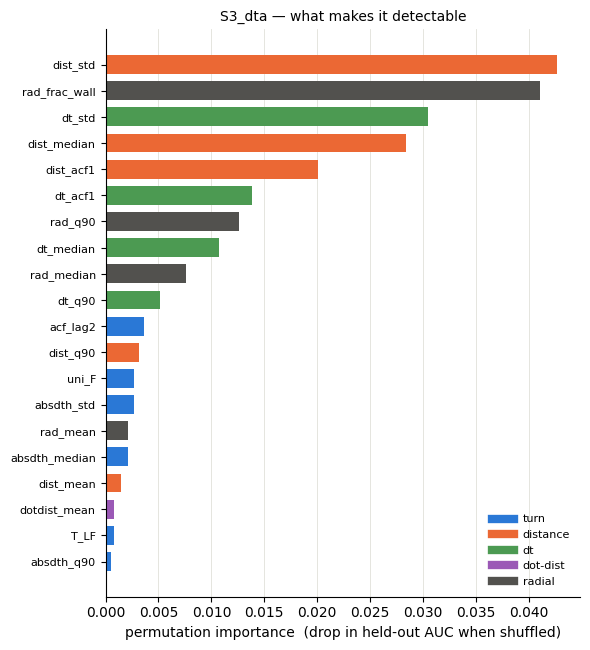

In [7]:
import sys; sys.path.insert(0, ".")     # notebook is in Model/, next to the script
from rollout_model1_local import run, plot_importances

_, c = run(ckpt_dir="model1_checkpoints", arms="S3_dta", skip_panel=True, importances=True)
plot_importances(c)



arms filter ['S1_dta'] -> writing panelB_model1_S1_dta.csv / c2st_model1_S1_dta.csv
15 (checkpoint, fish) rollout jobs, R=skipped, c2st_reps=8, jobs=19  (120 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
  [########################] 15/15     38s elapsed  ~   0s left   rollouts · S1_dta_fold2 fish 5              
panel skipped (39s of C2ST rollouts); panelB_model1_S1_dta.csv left as it was
  [########################] 1/1    148s elapsed  ~   0s left   c2st done                                     
wrote c2st_model1_S1_dta.csv in 148s

C2ST AUC, GroupKFold by fish (0.5 = indistinguishable, lower = better):
         c2st  c2st_traj  c2st_traj_se  c2st_traj_eq  c2st_neg
arm                                                           
S1_dta  0.618     0.8662        0.0022        0.8291     0.516

negative control (real vs real): 0.5160   -- at the 0.5 floor, so the AUCs above are model signal

dispersion, gen/real (1.0 = matched, <1 too typica

dist_std          0.029585
rad_frac_wall     0.028167
dt_acf1           0.025596
dist_median       0.023668
dist_acf1         0.019780
dt_std            0.018555
dist_q90          0.011399
rad_q90           0.008491
dt_median         0.007708
dt_q90            0.004915
rad_median        0.004640
absdth_median     0.004221
dist_mean         0.004103
absdth_std        0.003062
dotdist_median    0.002148
T_LF              0.001986
absdth_q90        0.001817
dotdist_std       0.001414
T_LR              0.000890
acf_lag2          0.000664
Name: importance, dtype: float64

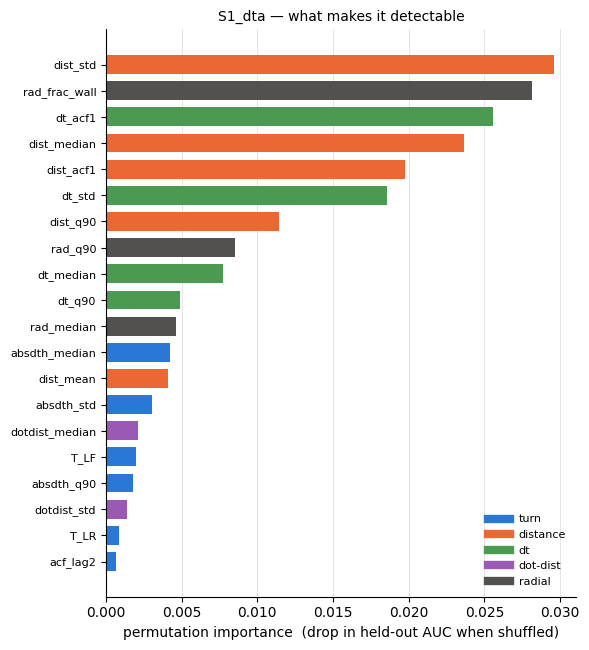

In [8]:
import sys; sys.path.insert(0, ".")     # notebook is in Model/, next to the script
from rollout_model1_local import run, plot_importances

_, c = run(ckpt_dir="model1_checkpoints", arms="S1_dta", skip_panel=True, importances=True)
plot_importances(c)



## Model 2 — MLP, 1 layer, joint head -> adding the rej to match tail of r/R distrbution

- **Guardrail** to stay in the dish
- **Generation-time fixes** rej
- **Head ordering** tried all : angle, distance, dt combinations
- **Stim representations 1 and 3**

### Input features

| # | block | config | dims |
|---|---|---|---|
| 1 | turn history | `K = 8` | 8 |
| 2 | lag validity | `lag_valid='scalar'` | 1 |
| 3 | stimulus | `stim_mode` — see below | 6 · 7 · 13 · 18 |
| 4 | wall | `use_border=True`, raw | 3 |
| 5 | kinematic history | `use_kin=True`, `K_kin = 3` | 6 |
| 6 | block clock | `clock_mode='exp'`, `clock_tau_s = 4` | 1 |
| | **total** | | **25 · 26 · 32 · 37** |

**Off:** symbols, stimulus memory (`K_stim`), adaptation (`use_adapt`). The last two are
deliberate — `K_stim`'s first column is time-since-onset, which duplicates the clock, and
`use_adapt` feeds the *change* in `dot_prox` where the stimulus block already feeds its level.
Both are later arms, and both should be tested **against** the clock rather than alongside it.

**Not an input:** the per-fish latent `z`, which enters as a bias offset on the head locations
and is drawn from `N(0, I)` at generation. Never feed `fish_id`.

### Defaults — now correct, no longer a checklist

These were traps; they are now the defaults, so Model 1 needs no special handling:

| | default |
|---|---|
| frame | `phi_ref='travel'`, `psi_ref='travel'` on new models |
| data | `evaluate.load_bouts()` → `clean_data/bouts_clean.csv`, resolved against the repo root |
| masking | `build_border_records(..., active_only=True)` |
| history | `_history_block`, `_kin_history_block` and `_lagvalid_block` pad from `run_pos`, so no lag reaches across a quiescence gap |

⚠ **One live gotcha remains.** A checkpoint saved *without* `phi_ref` / `psi_ref` reloads as
`'ori'` — deliberately, so an archived model comes back in the frame it was trained in. That
means a stored number is only comparable to a new one if both frames match; check the blob
rather than assuming.

Passing the old `data/bouts_GsizeMotionSingle.csv` now **raises** instead of silently
unmasking, and every run-aware path falls back to its flat form when `run_pos` is absent — so
archived configs stay bit-identical, verified.

In [1]:
# rej = GENERATION-TIME wall rejection: any bout whose landing point falls 2-10 mm from the wall is
# redrawn (max 20 redraws). Read straight from the rej checkpoint so the band is exactly rej's.
# Its centre_bias is bulk 0 / shell 0 -- inert -- so wall_reject is the whole mechanism.
# No retraining: the same 60 checkpoints, with the rejection rule merged into each model at load.
import sys; sys.path.insert(0, ".")          # notebook is in Model/, next to the script
from rollout_model1_local import run, plot_importances
import torch, fit_MLP_mix as MX              # scripts/ is on sys.path once the line above ran
MX._numpy2_unpickle_compat()
_rej = torch.load("../notebooks/_zip_analyse/ladder_psib_rej.pt", map_location="cpu",
                  weights_only=False)
REJ = {"wall_reject": dict(_rej["cfg_feat"]["wall_reject"])}
REJ

{'wall_reject': {'d0': 2.0,
  'd1': 10.0,
  'max_draws': 20,
  'draws_per_bout': 1.0231104795720583,
  'fallback_frac': 0.0}}

In [ ]:
# Same 12 arms (S1, S3 x 6 head orderings), rej's rejection added to every one.
# Writes panelB_model1_rej.csv / c2st_model1_rej.csv with arms named e.g. S3_dta_rej -- the
# plain run's files are untouched. The row to watch is wall_frac_gap (share of bouts past r/R 0.85).
panel_rej, c2st_rej = run(ckpt_dir="model1_checkpoints", R=20, jobs=8, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
180 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=19  (5,040 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)


ImportError: DLL load failed while importing _direct: The paging file is too small for this operation to complete.

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S3_dta'] -> writing panelB_model1_rej_S3_dta.csv / c2st_model1_rej_S3_dta.csv
15 (checkpoint, fish) rollout jobs, R=skipped, c2st_reps=8, jobs=19  (120 rollouts total)
  [########################] 15/15     42s elapsed  ~   0s left   rollouts · S3_dta_fold2 fish 5              
panel skipped (43s of C2ST rollouts); panelB_model1_rej_S3_dta.csv left as it was
  [########################] 1/1    135s elapsed  ~   0s left   c2st done                                     
wrote c2st_model1_rej_S3_dta.csv in 135s

C2ST AUC, GroupKFold by fish (0.5 = indistinguishable, lower = better):
              c2st  c2st_traj  c2st_traj_se  c2st_traj_eq  c2st_neg
arm                                                                
S3_dta_rej  0.6356     0.8649         0.001        0.8123     0.516

negative control (real vs real): 0.5160   -- at the 0.5 floor, so the AUCs abov

dist_std         0.035924
dist_median      0.027164
dt_std           0.021690
dist_acf1        0.021371
rad_median       0.013448
dt_acf1          0.010257
dt_median        0.009084
dotdist_std      0.005915
dist_q90         0.005532
dotdist_q90      0.004890
rad_mean         0.003984
absdth_median    0.003487
uni_F            0.003355
dt_q90           0.003239
rad_frac_wall    0.002684
T_LF             0.002446
absdth_std       0.002146
T_LR             0.002066
dt_mean          0.001903
dist_mean        0.001652
Name: importance, dtype: float64

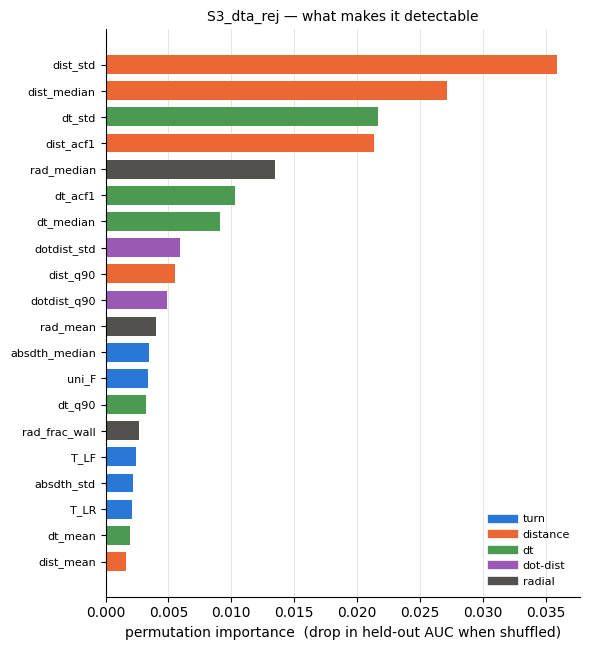

In [ ]:
_, c = run(ckpt_dir="model1_checkpoints", arms="S1_dta", cfg_override=REJ, tag="rej",
           skip_panel=True, importances=True)
plot_importances(c)

  rolled out fish 15/15
feature      between-fish SD         within-fish SD         fish-mean level         pooled SD       
                 real    gen      real    gen      real    gen       real    gen
dist_std         1.64  0.347      1.47   1.89      6.58   7.08        2.2   1.92
dt_std          0.216 0.0281     0.308   0.32     0.799  0.975      0.362  0.322
dt_acf1        0.0398 0.0179      0.15  0.159    0.0733  0.157       0.15  0.161
dist_acf1        0.05 0.0197     0.145  0.162     0.198  0.276      0.154  0.163


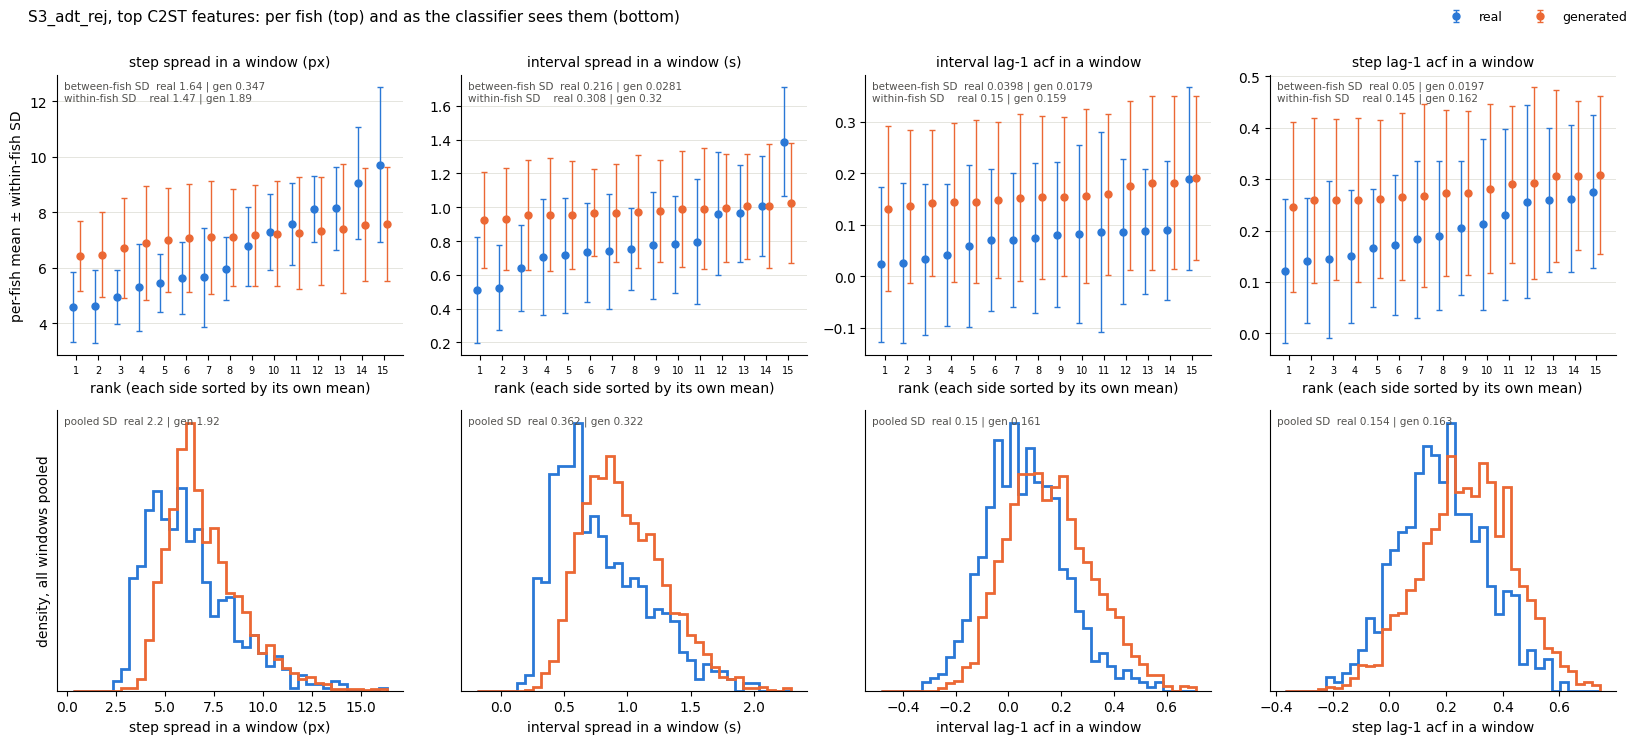

In [3]:
# Why dist_std / dt_std / dt_acf1 give the model away. These are the classifier's actual inputs:
# per-window features of S3_adt_rej rollouts (each fish rolled out by the fold model that never saw
# it, rej band on) against the same fish's real windows.
import sys, json
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, ".")
import rollout_model1_local                         # puts ../scripts on sys.path
import evaluate as E, fit_MLP_border as MB, fit_MLP_mix as MX, generative_metrics as GM
MX._numpy2_unpickle_compat()

# Which model to plot. Latent run:  CKPT_DIR, ARM = "model2z_checkpoints", "S3_adt_z2"
CKPT_DIR, ARM, REPS = "model1_checkpoints", "S3_adt", 2
REJ_BAND = {"d0": 2.0, "d1": 10.0, "max_draws": 20}
FEATS = [("dist_std", "step spread in a window (px)"),
         ("dt_std", "interval spread in a window (s)"),
         ("dt_acf1", "interval lag-1 acf in a window"),
         ("dist_acf1", "step lag-1 acf in a window")]
BLUE, ORANGE, INK2, GRID = "#2a78d6", "#eb6834", "#52514e", "#e1e0d9"

recs = MB.build_border_records(E.load_bouts())
mani = json.loads(open(f"{CKPT_DIR}/manifest_model1.json").read())
held = {int(f): e["file"] for e in mani if e["file"].startswith(ARM + "_fold") for f in e["heldout"]}
models, real, gen = {}, {}, {}
for i, (f, ck) in enumerate(sorted(held.items()), 1):
    if ck not in models:
        m = MX.load_mix(f"{CKPT_DIR}/{ck}")
        m._cfg_feat = {**m._cfg_feat, "wall_reject": REJ_BAND}
        models[ck] = m
    w = GM.c2st_windows_for_fish(models[ck], recs[f], f, seed=0, reps=REPS)["traj"]
    real[f], gen[f] = w[0][0], np.vstack([g for _, g in w])
    print(f"\r  rolled out fish {i}/{len(held)}", end="", flush=True)
print()
names = GM.traj_names_for_dim(next(iter(real.values())).shape[1])
FISH = sorted(real)

fig, ax = plt.subplots(2, len(FEATS), figsize=(4.1 * len(FEATS), 7.4))
print(f"{'feature':<11}{'between-fish SD':>17}{'':>7}{'within-fish SD':>16}{'':>7}"
      f"{'fish-mean level':>17}{'':>7}{'pooled SD':>11}{'':>7}")
print(f"{'':<11}" + "".join(f"{'real':>10}{'gen':>7}" for _ in range(3)) + f"{'real':>11}{'gen':>7}")
for j, (col, lab) in enumerate(FEATS):
    k = names.index(col)
    mr = np.array([real[f][:, k].mean() for f in FISH]); sr = np.array([real[f][:, k].std() for f in FISH])
    mg = np.array([gen[f][:, k].mean() for f in FISH]);  sg = np.array([gen[f][:, k].std() for f in FISH])
        # EACH side sorted by its own mean: a generated fish has no link to a real one (the latent draws a
    # new individual per rollout), so compare the two sets rank against rank.
    o, og = np.argsort(mr), np.argsort(mg)
    x = np.arange(len(FISH))
    a = ax[0, j]                                   # per fish: dot = fish mean, bar = that fish's spread
    a.errorbar(x - .16, mr[o], yerr=sr[o], fmt="o", ms=5, color=BLUE, capsize=2, lw=1, label="real")
    a.errorbar(x + .16, mg[og], yerr=sg[og], fmt="o", ms=5, color=ORANGE, capsize=2, lw=1,
               label="generated")
    a.set_xticks(x); a.set_xticklabels(x + 1, fontsize=7)
    a.set_xlabel("rank (each side sorted by its own mean)"); a.set_title(lab, fontsize=10)

    a.grid(axis="y", color=GRID, lw=.6); a.set_axisbelow(True)
    a.text(.02, .98, f"between-fish SD  real {mr.std(ddof=1):.3g} | gen {mg.std(ddof=1):.3g}\n"
                     f"within-fish SD    real {sr.mean():.3g} | gen {sg.mean():.3g}",
           transform=a.transAxes, va="top", fontsize=7.5, color=INK2)
    pr = np.concatenate([real[f][:, k] for f in FISH])      # what the classifier sees: all windows
    pg = np.concatenate([gen[f][:, k] for f in FISH])
    lo, hi = np.quantile(pr, [.005, .995]); pad = .25 * (hi - lo)
    b = np.linspace(lo - pad, hi + pad, 40)              # bins from REAL only: same for every model
    a = ax[1, j]                                         # <- bottom row
    a.hist(np.clip(pr, b[0], b[-1]), b, density=True, histtype="step", lw=2, color=BLUE)
    a.hist(np.clip(pg, b[0], b[-1]), b, density=True, histtype="step", lw=2, color=ORANGE)


    a.set_xlabel(lab); a.set_yticks([])
    a.text(.02, .98, f"pooled SD  real {pr.std():.3g} | gen {pg.std():.3g}", transform=a.transAxes,
           va="top", fontsize=7.5, color=INK2)
    print(f"{col:<11}{mr.std(ddof=1):>10.3g}{mg.std(ddof=1):>7.3g}{sr.mean():>10.3g}{sg.mean():>7.3g}"
          f"{mr.mean():>10.3g}{mg.mean():>7.3g}{pr.std():>11.3g}{pg.std():>7.3g}")
ax[0, 0].set_ylabel("per-fish mean ± within-fish SD")
ax[1, 0].set_ylabel("density, all windows pooled")
for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False)
h, l = ax[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", ncol=2, frameon=False, fontsize=9)
fig.suptitle(f"{ARM}_rej, top C2ST features: per fish (top) and as the classifier sees them (bottom)",
             x=.02, ha="left", y=1.0, fontsize=11)
fig.tight_layout(); plt.show()

### Why step spread and interval spread give the model away, and why the two acf features are a different problem

**Top row:** one point per fish. The dot is that fish's mean over its 60-bout windows, and the bar is how much it varies from window to window. Blue is the real fish. Orange is the same fish rolled out by the S3_adt_rej fold model that never saw it. **Bottom row:** the same windows pooled over all fish, which is what the classifier actually sees.

**Step spread and interval spread (`dist_std`, `dt_std`) show the missing individuality.** Real fish differ from each other. A calm fish's within-window step spread is ~4.6 px and a vigorous one's ~9.7 px (between-fish SD **1.64 px**), while every generated fish sits at ~7 px (between-fish SD **0.35 px**). *Within* one fish the window-to-window variation is about right (1.85 vs 1.47 px). Pooled, the real distribution is wider and contains a block of low values from the calm fish (7, 5, 2, 6) that no generated window ever reaches. A classifier trained on 12 fish learns that a step spread of ~4 px only comes from a real fish, and since that holds whatever the fish, it carries over to the 3 held-out fish. Interval spread is the same story (between-fish SD 0.216 s real vs 0.031 s generated).

**Interval and step lag-1 acf (`dt_acf1`, `dist_acf1`) are *not* individuality.** Real fish barely differ on them (between-fish SD 0.04). The difference is the **level**: consecutive generated intervals are about twice as correlated as real ones (fish mean 0.160 vs 0.073), and steps are too (0.28 vs 0.20), so every generated fish sits at the top of the real range. That is short-range over-persistence, most likely the model feeding its own last 3 steps and intervals back in (`K_kin = 3`), which makes consecutive bouts too alike in a free run. A per-fish latent would not touch it. Damping that feedback might (`kin_fb_calib` in the old lineage), but it once also halved the distance dispersion, so watch `var_*` if you try it.

**Why head order changes neither.** Head order sets how Δθ, distance and dt depend on each other *inside one bout*. The differences between fish and the persistence from one bout to the next live elsewhere, which is why all 12 orderings land at 0.850–0.865.

## Model 3 — MLP, 1 layer, joint head -> adding the rej to match tail of r/R distrbution, adding indivituality latent

- **Guardrail** to stay in the dish
- **Generation-time fixes** rej
- **Head ordering** tried all : angle, distance, dt combinations
- **Stim representations 1 and 3**
- **Individuality latent (m=2)**

### Input features

| # | block | config | dims |
|---|---|---|---|
| 1 | turn history | `K = 8` | 8 |
| 2 | lag validity | `lag_valid='scalar'` | 1 |
| 3 | stimulus | `stim_mode` — see below | 6 · 7 · 13 · 18 |
| 4 | wall | `use_border=True`, raw | 3 |
| 5 | kinematic history | `use_kin=True`, `K_kin = 3` | 6 |
| 6 | block clock | `clock_mode='exp'`, `clock_tau_s = 4` | 1 |
| | **total** | | **25 · 26 · 32 · 37** |

**Off:** symbols, stimulus memory (`K_stim`), adaptation (`use_adapt`). The last two are
deliberate — `K_stim`'s first column is time-since-onset, which duplicates the clock, and
`use_adapt` feeds the *change* in `dot_prox` where the stimulus block already feeds its level.
Both are later arms, and both should be tested **against** the clock rather than alongside it.

**Not an input:** the per-fish latent `z`, which enters as a bias offset on the head locations
and is drawn from `N(0, I)` at generation. Never feed `fish_id`.

### Defaults — now correct, no longer a checklist

These were traps; they are now the defaults, so Model 1 needs no special handling:

| | default |
|---|---|
| frame | `phi_ref='travel'`, `psi_ref='travel'` on new models |
| data | `evaluate.load_bouts()` → `clean_data/bouts_clean.csv`, resolved against the repo root |
| masking | `build_border_records(..., active_only=True)` |
| history | `_history_block`, `_kin_history_block` and `_lagvalid_block` pad from `run_pos`, so no lag reaches across a quiescence gap |

⚠ **One live gotcha remains.** A checkpoint saved *without* `phi_ref` / `psi_ref` reloads as
`'ori'` — deliberately, so an archived model comes back in the frame it was trained in. That
means a stored number is only comparable to a new one if both frames match; check the blob
rather than assuming.

Passing the old `data/bouts_GsizeMotionSingle.csv` now **raises** instead of silently
unmasking, and every run-aware path falls back to its flat form when `run_pos` is absent — so
archived configs stay bit-identical, verified.

In [1]:
# rej = GENERATION-TIME wall rejection: any bout whose landing point falls 2-10 mm from the wall is
# redrawn (max 20 redraws). Read straight from the rej checkpoint so the band is exactly rej's.
# Its centre_bias is bulk 0 / shell 0 -- inert -- so wall_reject is the whole mechanism.
# No retraining: the same 60 checkpoints, with the rejection rule merged into each model at load.
import sys; sys.path.insert(0, ".")          # notebook is in Model/, next to the script
from rollout_model1_local import run, plot_importances
import torch, fit_MLP_mix as MX              # scripts/ is on sys.path once the line above ran
MX._numpy2_unpickle_compat()
_rej = torch.load("../notebooks/_zip_analyse/ladder_psib_rej.pt", map_location="cpu",
                  weights_only=False)
REJ = {"wall_reject": dict(_rej["cfg_feat"]["wall_reject"])}
REJ

{'wall_reject': {'d0': 2.0,
  'd1': 10.0,
  'max_draws': 20,
  'draws_per_bout': 1.0231104795720583,
  'fallback_frac': 0.0}}

In [2]:
# Latent run: S1_adt_z2 + S3_adt_z2, 5 folds each. rej is already built into these checkpoints, so
# the override only adds the _rej tag -> arms S1_adt_z2_rej / S3_adt_z2_rej, and
# panelB_model1_rej.csv / c2st_model1_rej.csv inside model2z_checkpoints/.
panel_z, c2st_z = run(ckpt_dir="model2z_checkpoints", R=20, cfg_override=REJ, tag="rej")


generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
30 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=19  (840 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
  [########################] 30/30    470s elapsed  ~   0s left   rollouts · S3_adt_z2_fold2 fish 5           
wrote panelB_model1_rej.csv  (30 rows) in 472s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S1_adt_z2_rej  S3_adt_z2_rej
abs_dtheta_w1                  8.7330         8.9005
symbol_js                      0.0123         0.0116
dt_w1                          0.3580         0.3940
dist_w1                        4.5311         4.2754
trans_js                       0.0144         0.0136
acf_l2                         0.0520         0.0499
runlen_w1                      0.1875         0.1712
bigram_H_gap                   0.1090         0.1037
tuning_mse                

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S1_adt_z2'] -> writing panelB_model1_rej_S1_adt_z2.csv / c2st_model1_rej_S1_adt_z2.csv
15 (checkpoint, fish) rollout jobs, R=skipped, c2st_reps=8, jobs=19  (120 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
  [########################] 15/15     38s elapsed  ~   0s left   rollouts · S1_adt_z2_fold2 fish 5           
panel skipped (39s of C2ST rollouts); panelB_model1_rej_S1_adt_z2.csv left as it was
  [########################] 1/1    174s elapsed  ~   0s left   c2st done                                     
wrote c2st_model1_rej_S1_adt_z2.csv in 174s

C2ST AUC, GroupKFold by fish (0.5 = indistinguishable, lower = better):
                 c2st  c2st_traj  c2st_traj_se  c2st_traj_eq  c2st_neg
arm                                                                   
S1_adt_z2_rej  0.5655     0.7239        0.0182    

dt_std            0.029559
dt_median         0.029525
rad_median        0.022399
dt_acf1           0.015844
rad_mean          0.014472
rad_frac_wall     0.010806
dt_mean           0.007625
dotdist_q90       0.004862
absdth_std        0.004193
dotdist_median    0.004173
dotdist_mean      0.004115
dt_q90            0.004057
rad_q90           0.002672
dotdist_std       0.002143
dotdist_acf1      0.001793
T_LR              0.001184
acf_lag2          0.001109
T_LF              0.001068
dist_std          0.000876
T_FF              0.000244
Name: importance, dtype: float64

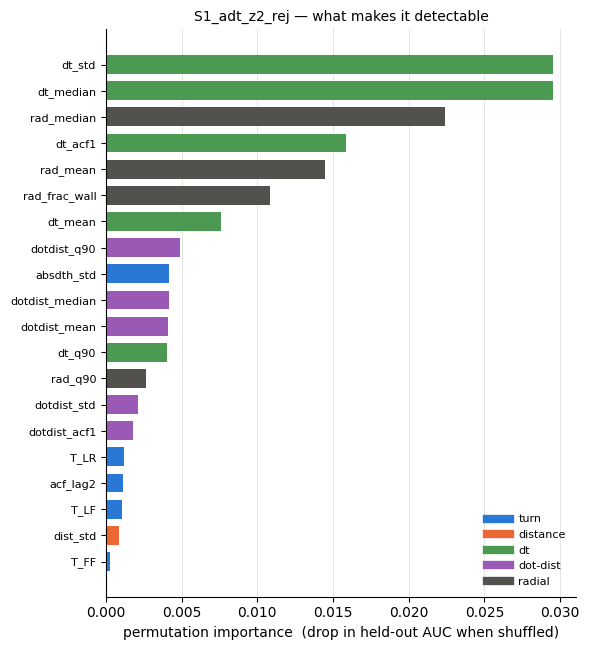

In [3]:
_, c = run(ckpt_dir="model2z_checkpoints", arms="S1_adt_z2", cfg_override=REJ, tag="rej",
           skip_panel=True, importances=True)
plot_importances(c)


  rolled out fish 15/15
feature      between-fish SD         within-fish SD         fish-mean level         pooled SD       
                 real    gen      real    gen      real    gen       real    gen
dist_std         1.64   1.96      1.47   1.29      6.58   5.99        2.2   2.33
dt_std          0.216  0.167     0.308  0.278     0.799  0.889      0.362  0.327
dt_acf1        0.0398 0.0295      0.15  0.149    0.0733  0.127       0.15  0.151
dist_acf1        0.05 0.0527     0.145  0.151     0.198  0.205      0.154  0.158


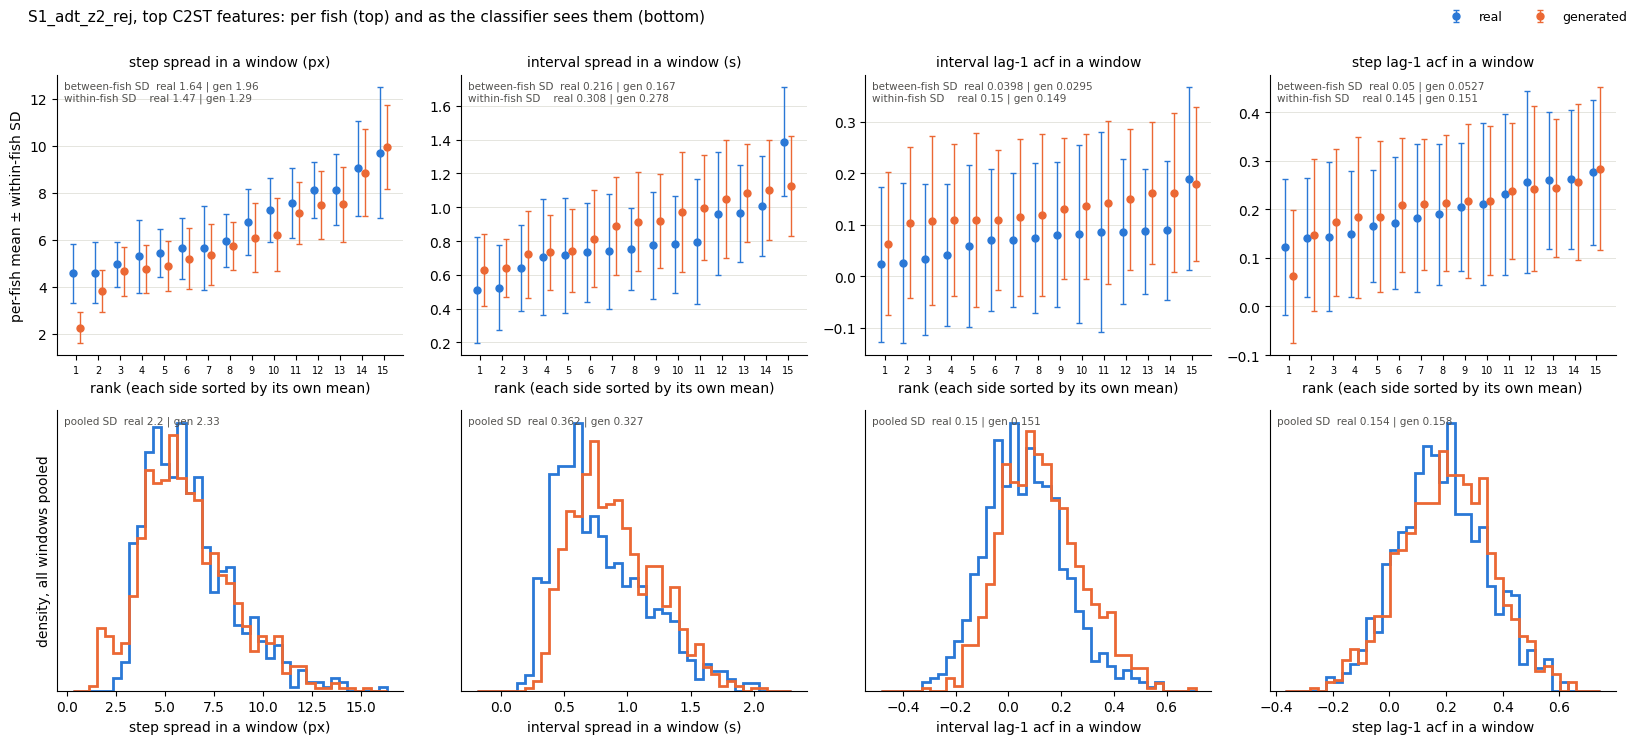

In [4]:
# Why dist_std / dt_std / dt_acf1 give the model away. These are the classifier's actual inputs:
# per-window features of S3_adt_rej rollouts (each fish rolled out by the fold model that never saw
# it, rej band on) against the same fish's real windows.
import sys, json
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, ".")
import rollout_model1_local                         # puts ../scripts on sys.path
import evaluate as E, fit_MLP_border as MB, fit_MLP_mix as MX, generative_metrics as GM
MX._numpy2_unpickle_compat()

# Which model to plot. Latent run:  CKPT_DIR, ARM = "model2z_checkpoints", "S3_adt_z2"
# Which model: plain "model1_checkpoints"/"S3_adt", or latent "model2z_checkpoints"/"S1_adt_z2".
CKPT_DIR, ARM = "model2z_checkpoints", "S1_adt_z2"
# A latent model draws a NEW individual (z) every rollout. Stacking 2 rollouts per fish slot would
# average two individuals and shrink exactly the between-fish spread this plot measures.
REPS = 1 if "_z" in ARM else 2
REJ_BAND = {"d0": 2.0, "d1": 10.0, "max_draws": 20}
FEATS = [("dist_std", "step spread in a window (px)"),
         ("dt_std", "interval spread in a window (s)"),
         ("dt_acf1", "interval lag-1 acf in a window"),
         ("dist_acf1", "step lag-1 acf in a window")]
BLUE, ORANGE, INK2, GRID = "#2a78d6", "#eb6834", "#52514e", "#e1e0d9"

recs = MB.build_border_records(E.load_bouts())
mani = json.loads(open(f"{CKPT_DIR}/manifest_model1.json").read())
held = {int(f): e["file"] for e in mani if e["file"].startswith(ARM + "_fold") for f in e["heldout"]}
models, real, gen = {}, {}, {}
for i, (f, ck) in enumerate(sorted(held.items()), 1):
    if ck not in models:
        m = MX.load_mix(f"{CKPT_DIR}/{ck}")
        m._cfg_feat = {**m._cfg_feat, "wall_reject": REJ_BAND}
        models[ck] = m
    w = GM.c2st_windows_for_fish(models[ck], recs[f], f, seed=0, reps=REPS)["traj"]
    real[f], gen[f] = w[0][0], np.vstack([g for _, g in w])
    print(f"\r  rolled out fish {i}/{len(held)}", end="", flush=True)
print()
names = GM.traj_names_for_dim(next(iter(real.values())).shape[1])
FISH = sorted(real)

fig, ax = plt.subplots(2, len(FEATS), figsize=(4.1 * len(FEATS), 7.4))
print(f"{'feature':<11}{'between-fish SD':>17}{'':>7}{'within-fish SD':>16}{'':>7}"
      f"{'fish-mean level':>17}{'':>7}{'pooled SD':>11}{'':>7}")
print(f"{'':<11}" + "".join(f"{'real':>10}{'gen':>7}" for _ in range(3)) + f"{'real':>11}{'gen':>7}")
for j, (col, lab) in enumerate(FEATS):
    k = names.index(col)
    mr = np.array([real[f][:, k].mean() for f in FISH]); sr = np.array([real[f][:, k].std() for f in FISH])
    mg = np.array([gen[f][:, k].mean() for f in FISH]);  sg = np.array([gen[f][:, k].std() for f in FISH])
        # EACH side sorted by its own mean: a generated fish has no link to a real one (the latent draws a
    # new individual per rollout), so compare the two sets rank against rank.
    o, og = np.argsort(mr), np.argsort(mg)
    x = np.arange(len(FISH))
    a = ax[0, j]                                   # per fish: dot = fish mean, bar = that fish's spread
    a.errorbar(x - .16, mr[o], yerr=sr[o], fmt="o", ms=5, color=BLUE, capsize=2, lw=1, label="real")
    a.errorbar(x + .16, mg[og], yerr=sg[og], fmt="o", ms=5, color=ORANGE, capsize=2, lw=1,
               label="generated")
    a.set_xticks(x); a.set_xticklabels(x + 1, fontsize=7)
    a.set_xlabel("rank (each side sorted by its own mean)"); a.set_title(lab, fontsize=10)

    a.grid(axis="y", color=GRID, lw=.6); a.set_axisbelow(True)
    a.text(.02, .98, f"between-fish SD  real {mr.std(ddof=1):.3g} | gen {mg.std(ddof=1):.3g}\n"
                     f"within-fish SD    real {sr.mean():.3g} | gen {sg.mean():.3g}",
           transform=a.transAxes, va="top", fontsize=7.5, color=INK2)
    pr = np.concatenate([real[f][:, k] for f in FISH])      # what the classifier sees: all windows
    pg = np.concatenate([gen[f][:, k] for f in FISH])
    lo, hi = np.quantile(pr, [.005, .995]); pad = .25 * (hi - lo)
    b = np.linspace(lo - pad, hi + pad, 40)              # bins from REAL only: same for every model
    a = ax[1, j]                                         # <- bottom row
    a.hist(np.clip(pr, b[0], b[-1]), b, density=True, histtype="step", lw=2, color=BLUE)
    a.hist(np.clip(pg, b[0], b[-1]), b, density=True, histtype="step", lw=2, color=ORANGE)


    a.set_xlabel(lab); a.set_yticks([])
    a.text(.02, .98, f"pooled SD  real {pr.std():.3g} | gen {pg.std():.3g}", transform=a.transAxes,
           va="top", fontsize=7.5, color=INK2)
    print(f"{col:<11}{mr.std(ddof=1):>10.3g}{mg.std(ddof=1):>7.3g}{sr.mean():>10.3g}{sg.mean():>7.3g}"
          f"{mr.mean():>10.3g}{mg.mean():>7.3g}{pr.std():>11.3g}{pg.std():>7.3g}")
ax[0, 0].set_ylabel("per-fish mean ± within-fish SD")
ax[1, 0].set_ylabel("density, all windows pooled")
for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False)
h, l = ax[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", ncol=2, frameon=False, fontsize=9)
fig.suptitle(f"{ARM}_rej, top C2ST features: per fish (top) and as the classifier sees them (bottom)",
             x=.02, ha="left", y=1.0, fontsize=11)
fig.tight_layout(); plt.show()